# Bayesian optimisation: choosing the next test temperature

Charpy specimens are expensive and finite. This notebook picks each next test
temperature to **reduce uncertainty** about the transition curve, rather than to find a
maximum — so the DBTT can be located from as few broken specimens as possible.

Two uncertainty-reduction acquisitions from the uncertainty-engine:

- **qNIPV** — negative integrated posterior variance. Picks the temperature that most
  reduces GP variance *averaged over the whole range*. Global, and more expensive.
- **PSD** — posterior standard deviation. Picks wherever the GP is least certain right
  now. Local and greedy.

In [1]:
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np

from dbtt import CharpySimulator, CharpySimulatorConfig
from dbtt.active_learning import DBTTActiveLearner, initial_design
from dbtt.plotting import plot_gp

## 1. The initial design

Start with the two limits of the testable range. They pin the lower and upper shelves,
which is what the transition sits *between* — with neither shelf, the curve is
unidentifiable.

In [2]:
BOUNDS = (-150.0, 100.0)
print("initial design:", initial_design(BOUNDS))

simulator = CharpySimulator(CharpySimulatorConfig.from_yaml("../configs/eurofer_eaf.yaml"))
# Acquisition-argmax effort. Raise for smoother proposals at higher cost.
BUDGET = {"raw_samples": 64, "num_restarts": 5}

learner = DBTTActiveLearner(simulator, bounds=BOUNDS, acquisition="qNIPV", **BUDGET)

print(f"tested so far: {learner.temperatures} C -> {learner.energies.round(1)} J")
print(f"mean GP uncertainty: {learner.mean_posterior_std():.1f} J")

initial design: [-150.  100.]


tested so far: [-150.  100.] C -> [  5.6 196.9] J
mean GP uncertainty: 101.6 J


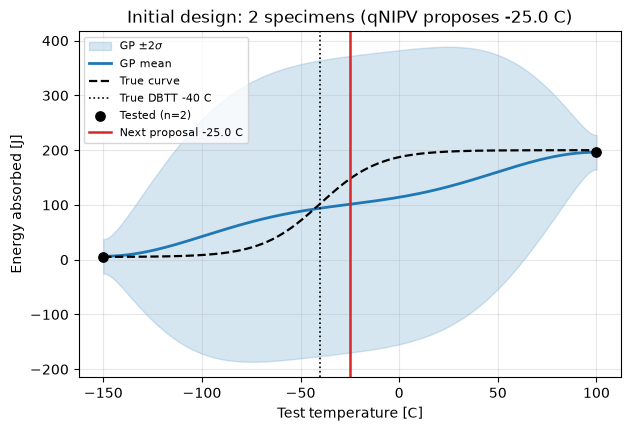

In [3]:
proposed, acq_value = learner.propose()
plot_gp(learner, simulator=simulator, proposed=proposed)
plt.title(f"Initial design: 2 specimens (qNIPV proposes {proposed:.1f} C)")
plt.show()

With only the two shelf points, the GP interpolates almost linearly between them and is
wildly uncertain across the whole transition. The acquisition sends us straight into the
middle.

## 2. One step at a time

Each iteration: ask the acquisition, break a specimen at that temperature, refit the GP.

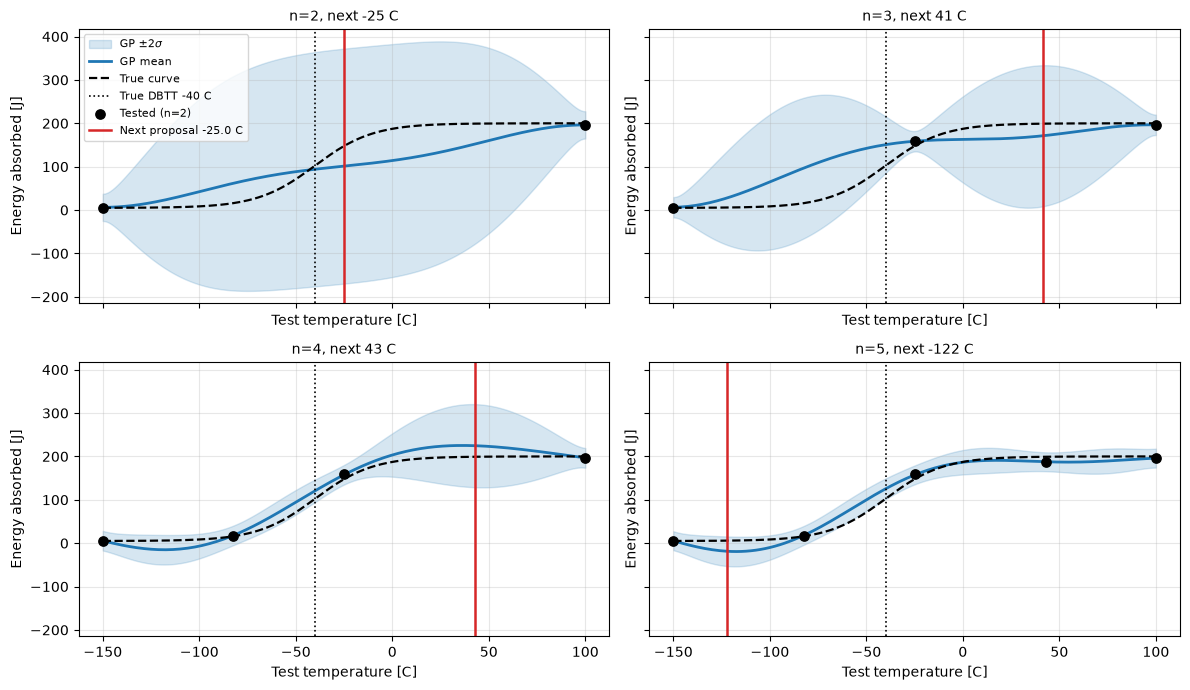

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey=True)

for i, ax in enumerate(axes.ravel()):
    proposed, _ = learner.propose()
    plot_gp(learner, simulator=simulator, proposed=proposed, ax=ax,
            show_legend=(i == 0))
    ax.set_title(f"n={len(learner.temperatures)}, next {proposed:.0f} C", fontsize=10)
    learner.step()

plt.tight_layout()
plt.show()

In [5]:
print(f"{'step':>4} {'T [C]':>9} {'energy [J]':>11} {'acq value':>12} {'n':>4}")
for s in learner.history:
    print(f"{s.index:>4} {s.temperature:>9.2f} {s.energy:>11.2f} {s.acquisition_value:>12.2f} {s.n_observations:>4}")

print(f"\nmean GP uncertainty now {learner.mean_posterior_std():.1f} J")
print(f"DBTT estimate {learner.dbtt_estimate():.1f} C (truth {simulator.dbtt:g} C)")

step     T [C]  energy [J]    acq value    n
   0    -25.00      158.93     -5349.04    3
   1    -82.42       16.37     -1762.33    4
   2     42.87      186.95       -99.25    5
   3   -122.23        7.10       -76.92    6

mean GP uncertainty now 13.1 J
DBTT estimate -47.0 C (truth -40 C)


## 3. qNIPV vs PSD

Run both from the same initial design and watch the uncertainty come down.

In [6]:
N_STEPS = 6
runs = {}

for acquisition in ["qNIPV", "PSD"]:
    al = DBTTActiveLearner(
        CharpySimulator(CharpySimulatorConfig.from_yaml("../configs/eurofer_eaf.yaml")),
        bounds=BOUNDS, acquisition=acquisition, **BUDGET,
    )
    trace = [al.mean_posterior_std()]
    for _ in range(N_STEPS):
        al.step()
        trace.append(al.mean_posterior_std())
    runs[acquisition] = {"learner": al, "trace": trace}
    print(f"{acquisition:6s} {trace[0]:6.1f} -> {trace[-1]:5.1f} J | "
          f"DBTT estimate {al.dbtt_estimate():6.1f} C")

qNIPV   101.6 ->   9.6 J | DBTT estimate  -43.2 C


PSD     101.6 ->  20.0 J | DBTT estimate  -48.2 C


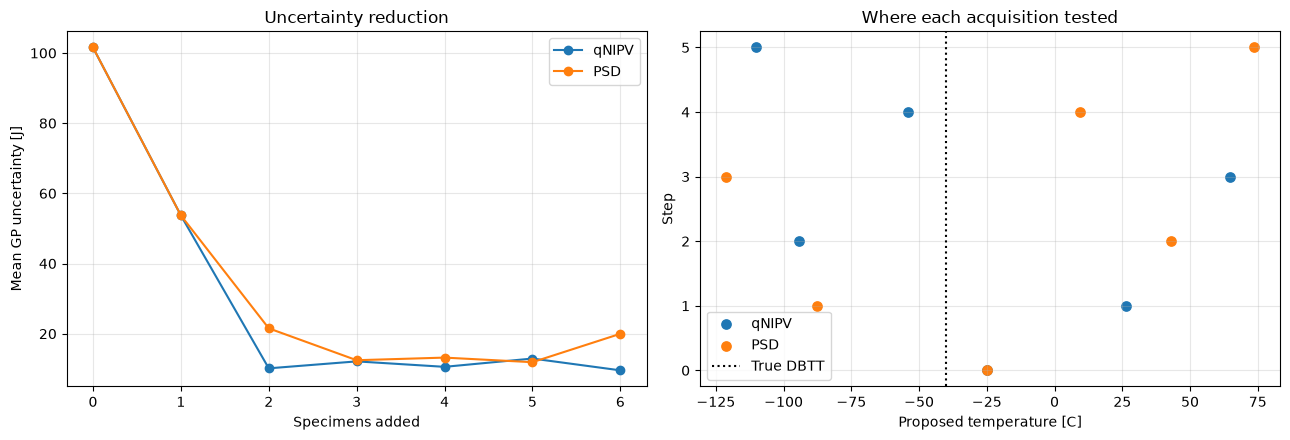

In [7]:
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4.5))

for acquisition, run in runs.items():
    left.plot(range(len(run["trace"])), run["trace"], marker="o", label=acquisition)
left.set_xlabel("Specimens added"); left.set_ylabel("Mean GP uncertainty [J]")
left.set_title("Uncertainty reduction"); left.grid(alpha=0.3); left.legend()

for acquisition, run in runs.items():
    right.scatter(run["learner"].temperatures[2:],
                  np.arange(len(run["learner"].temperatures) - 2),
                  label=acquisition, s=45)
right.axvline(simulator.dbtt, color="k", ls=":", label="True DBTT")
right.set_xlabel("Proposed temperature [C]"); right.set_ylabel("Step")
right.set_title("Where each acquisition tested"); right.grid(alpha=0.3); right.legend()

plt.tight_layout(); plt.show()

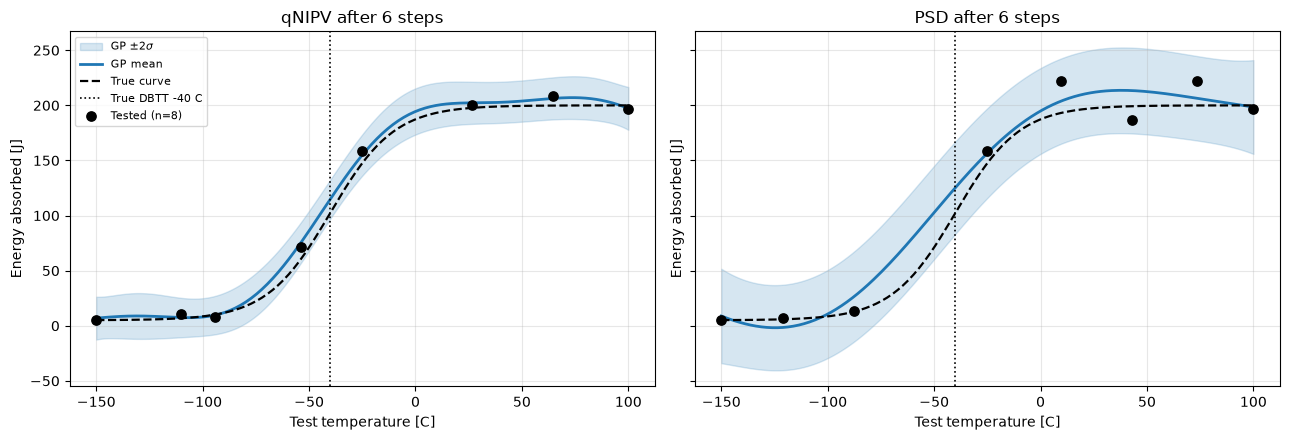

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, (acquisition, run) in zip(axes, runs.items()):
    plot_gp(run["learner"], simulator=simulator, ax=ax, show_legend=(ax is axes[0]))
    ax.set_title(f"{acquisition} after {N_STEPS} steps")
plt.tight_layout(); plt.show()

## 4. What to read from this

- **Both acquisitions find the transition without being told where it is.** From two
  shelf points they immediately test near the middle, then fill in.
- **Which acquisition "wins" flips between runs.** Each column above is a single noise
  realisation of a short campaign, and the ordering is not stable: repeat runs of this
  notebook have put qNIPV ahead on one seed and PSD ahead on another. Do not read a
  ranking off one run. Ranking them properly means repeating both over many seeds and
  comparing distributions — worth doing before committing a real campaign to one
  acquisition, and deliberately not done here because it costs far more compute than the
  rest of this notebook combined.
- The two differ in *character* rather than reliably in quality: PSD greedily attacks the
  single least-known point, while qNIPV optimises variance integrated over the whole
  range and so spends more effort confirming the shelves.
- **The band plateaus rather than shrinking to zero.** The plotted spread is the
  *predictive* standard deviation, which includes test-to-test scatter. No amount of
  testing removes that, and the plateau height is the material's own measurement noise.
  (The latent-only spread would be the purer measure, but this GP's latent covariance is
  numerically singular and Cholesky fails on it — see `DBTTActiveLearner.posterior`.)
- **The DBTT read off the GP mean is an indicator, not a result.** It carries no
  uncertainty of its own. For a DBTT *with* an interval, fit the AHT to these points with
  `dbtt.recovery.recover` — notebook 02.

## Next

Notebook 04 does the same thing through the uncertainty-engine **SDK**, building the
active-learning workflow remotely rather than in-process.